# 06 — Estabilidad temporal y errores económicos

El notebook 05 mostró que LightGBM con Platt y BMR reduce el costo en los escenarios analizados, pero también dejó diferencias de calibración por monto. Ahora preguntamos si esos resultados se mantienen dentro de la validación posterior, dónde se concentra el fraude aprobado y cuánto dependen las acciones de probabilidades cercanas al límite económico.

Trabajamos con los scores y acciones verificados del 05: 42.047 operaciones, tres políticas y seis Ca hipotéticos. Este análisis es descriptivo sobre un bloque ya consultado. No carga modelos ni vuelve a entrenar, calibrar o seleccionar; tampoco puntúa test. Mantener tres subperiodos no convierte sus resultados en réplicas independientes ni demuestra deriva de concepto.

## 1. Diseño del diagnóstico y procedencia

Definimos tres subperiodos de igual duración, las bandas de monto del 05 y concentraciones superiores de 1, 5 y 10 fraudes aprobados. Conservamos todos los Ca; usamos Ca=10 únicamente como ilustración de las figuras temporales. La banda de frontera es 0,9 ≤ pA/Ca ≤ 1,1. Perturbamos p por factores 0,9, 1 y 1,1, recortando a [0,1]; no son intervalos de confianza ni nuevas probabilidades calibradas.

La configuración se registra antes de calcular estos diagnósticos. Es un protocolo local de desarrollo, no una preregistración independiente de lo observado previamente. Verificamos fuentes, datos y registros de la cadena anterior sin deserializar modelos.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import subprocess
import sys
from datetime import datetime, timezone
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").is_dir() and (p / "notebooks").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from fraud_cost.artifacts import sha256_file, verify_hashes, notebook_code_sha256
from fraud_cost.stability import (load_validation_evidence, temporal_periods, period_probabilities,
    period_costs, period_amount_calibration, missed_loss_concentration, boundary_sensitivity)

TABLES, FIGURES = ROOT / "results/tables", ROOT / "results/figures"
PERIOD_COUNT, EXAMPLE_CA = 3, 10
TOP_COUNTS, RELATIVE_BAND, FACTORS = (1, 5, 10), .10, (.9, 1., 1.1)
AMOUNT_EDGES = (0, 50, 100, 250, 500, 1000, np.inf)
scores, aligned, parent = load_validation_evidence(ROOT)
CA_GRID = tuple(parent["ca_grid"])
notebook_path = ROOT / "notebooks/06_estabilidad_y_errores_economicos.ipynb"
code_hash = notebook_code_sha256(notebook_path)
source_paths = ["src/fraud_cost/stability.py", "src/fraud_cost/artifacts.py", "src/fraud_cost/costs.py"]
source_hashes = {p: sha256_file(ROOT / p) for p in source_paths}
inputs = {p: sha256_file(ROOT / p) for p in ["results/tables/lightgbm_adopcion_config.json",
    "data/interim/lightgbm_validation_scores.parquet", "data/interim/lightgbm_validation_actions.parquet",
    "data/interim/split_manifest.parquet", "results/tables/lightgbm_costos_validation.csv"]}
protocol = {"planned_utc": datetime.now(timezone.utc).isoformat(), "period_count": PERIOD_COUNT,
    "period_rule": "equal_observed_duration_left_closed_last_right_closed", "ca_grid": list(CA_GRID),
    "example_ca": EXAMPLE_CA, "top_counts": list(TOP_COUNTS), "relative_boundary_band": RELATIVE_BAND,
    "probability_factors": list(FACTORS), "amount_edges": [str(x) for x in AMOUNT_EDGES],
    "notebook_code_sha256": code_hash, "input_sha256": inputs, "source_sha256": source_hashes,
    "development_validation_previously_consulted": True, "test_evaluated": False,
    "model_loaded": False, "new_model_fitted": False, "new_calibrator_fitted": False,
    "selection_changed": False, "costs_hypothetical": True}
protocol_path = TABLES / "estabilidad_protocolo.json"
protocol_path.write_text(json.dumps(protocol, ensure_ascii=False, indent=2), encoding="utf-8")
print("Scores verificados:", scores.shape, "; acciones:", sum(len(a) for a in aligned.values()))
print("Tres subperiodos, seis escenarios; sin cargar modelos ni puntuar test.")

Scores verificados: (42047, 7) ; acciones: 252282
Tres subperiodos, seis escenarios; sin cargar modelos ni puntuar test.


## 2. Tiempo y composición de las poblaciones

Los límites se calculan con TransactionDT, sin usar etiquetas. Instantes iguales permanecen juntos; el último límite incluye el máximo. Al tener igual duración, las cantidades de transacciones pueden diferir. Reportamos prevalencia y pérdida potencial observada para contextualizar AP y costos.

Calculamos las seis métricas predictivas raw/Platt en cada periodo. El costo por operación permite comparar periodos de distinto volumen. Cada referencia trivial se calcula en su propia población: sumamos costos y componentes, pero no porcentajes de ahorro ni mínimos de referencias.

In [2]:
data, periods = temporal_periods(scores, PERIOD_COUNT)
probabilities = period_probabilities(data)
costs = period_costs(data, aligned)
historical_costs = pd.read_csv(TABLES / "lightgbm_costos_validation.csv")
keys = ["administrative_cost_ca", "strategy"]
summed = costs.groupby(keys)[["cost_total_proxy", "administrative_cost_total", "missed_fraud_amount"]].sum().sort_index()
expected = historical_costs.set_index(keys)[summed.columns].sort_index()
np.testing.assert_allclose(summed, expected, atol=1e-8, rtol=1e-8)
assert periods.rows.sum() == len(scores) and periods.frauds.sum() == scores.isFraud.sum()
display(periods.round(5))
display(probabilities[["period", "probability", "average_precision", "brier_score", "log_loss",
    "recall_at_0_5", "precision_at_0_5", "legitimate_block_rate", "mean_probability"]].round(5))
display(costs.loc[costs.administrative_cost_ca.eq(EXAMPLE_CA), ["period", "strategy", "rows",
    "cost_per_transaction_proxy", "fraud_recall", "legitimate_block_rate", "savings_fraction_vs_fixed_proxy"]].round(5))

,period,boundary_start,boundary_end,end_inclusive,time_start,time_end,rows,frauds,fraud_rate,fraud_amount
0,1,11293020.0,11750738.0,False,11293020,11750710,14949,588,0.03933,101447.659
1,2,11750738.0,12208456.0,False,11750826,12208074,13820,436,0.03155,77835.917
2,3,12208456.0,12666174.0,True,12208546,12666174,13278,493,0.03713,75253.236


,period,probability,average_precision,brier_score,log_loss,recall_at_0_5,precision_at_0_5,legitimate_block_rate,mean_probability
0,1,raw,0.53358,0.02562,0.10117,0.32653,0.81356,0.00306,0.03034
1,1,platt,0.53358,0.02526,0.10003,0.34014,0.78740,0.00376,0.03314
2,2,raw,0.50981,0.02121,0.08437,0.25917,0.79021,0.00224,0.02495
3,2,platt,0.50981,0.02082,0.08333,0.30505,0.78235,0.00276,0.02749
4,3,raw,0.46494,0.02620,0.10704,0.26572,0.79878,0.00258,0.02733
5,3,platt,0.46494,0.02608,0.10607,0.27383,0.78488,0.00289,0.03000


,period,strategy,rows,cost_per_transaction_proxy,fraud_recall,legitimate_block_rate,savings_fraction_vs_fixed_proxy
18,1,fixed_0_5,14949,5.27376,0.34014,0.00376,0.00000
19,1,bmr,14949,2.00943,0.59014,0.06121,0.61898
20,1,cost_sensitive_tree,14949,3.12558,0.42347,0.07040,0.40733
21,2,fixed_0_5,13820,4.30161,0.30505,0.00276,0.00000
22,2,bmr,13820,1.61786,0.57798,0.04901,0.62389
23,2,cost_sensitive_tree,13820,2.68713,0.40367,0.06015,0.37532
24,3,fixed_0_5,13278,4.50514,0.27383,0.00289,0.00000
25,3,bmr,13278,2.39283,0.49493,0.06320,0.46887
26,3,cost_sensitive_tree,13278,3.17306,0.38540,0.06719,0.29568


## 3. Cómo cambian probabilidades y decisiones entre periodos

La media anunciada y la prevalencia ayudan a detectar desajustes globales, pero no prueban calibración condicional. AP puede variar con la composición y prevalencia. Una diferencia entre tres periodos consecutivos no demuestra por sí sola deriva ni superioridad estadística.

La figura económica utiliza Ca=10 por continuidad con el 05; las tablas conservan los seis escenarios. Leemos recall junto con intervención de legítimas y costo, sin buscar el periodo más favorable.

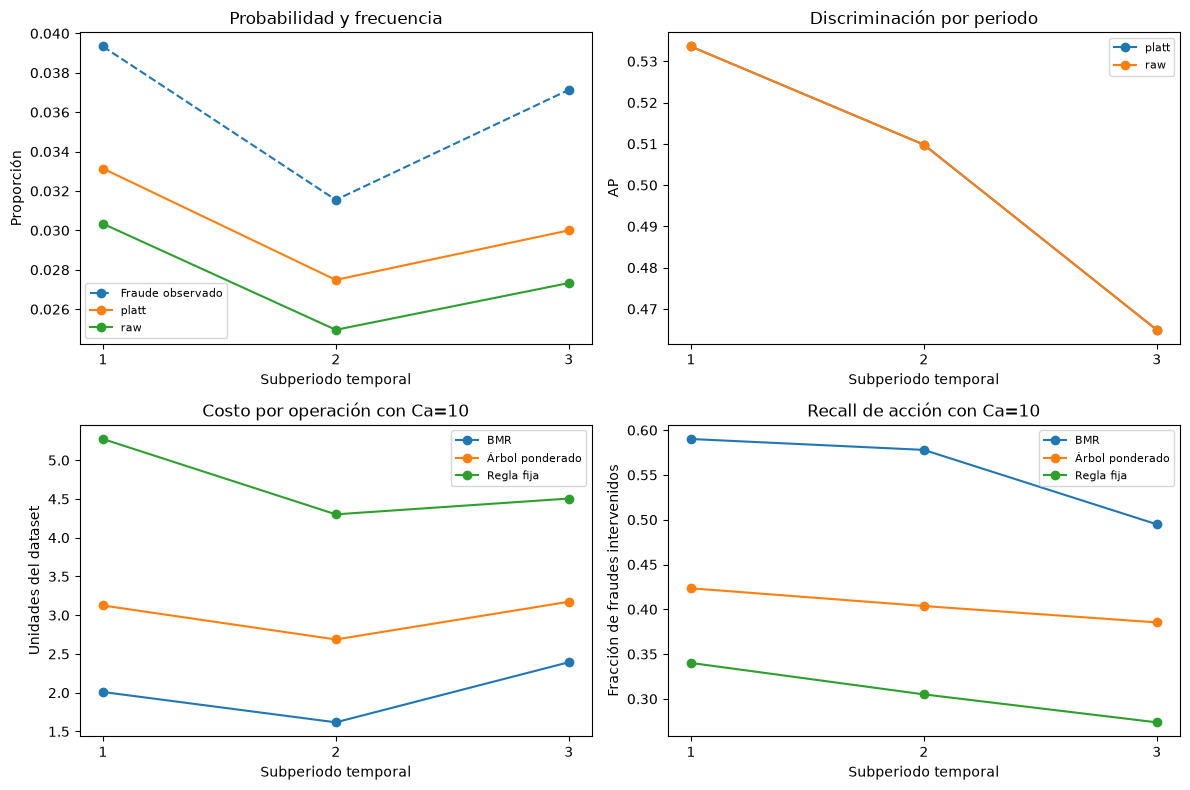

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(periods.period, periods.fraud_rate, "o--", label="Fraude observado")
for stage, group in probabilities.groupby("probability"):
    axes[0, 0].plot(group.period, group.mean_probability, "o-", label=stage)
    axes[0, 1].plot(group.period, group.average_precision, "o-", label=stage)
labels = {"fixed_0_5": "Regla fija", "bmr": "BMR", "cost_sensitive_tree": "Árbol ponderado"}
for policy, group in costs.loc[costs.administrative_cost_ca.eq(EXAMPLE_CA)].groupby("strategy"):
    axes[1, 0].plot(group.period, group.cost_per_transaction_proxy, "o-", label=labels[policy])
    axes[1, 1].plot(group.period, group.fraud_recall, "o-", label=labels[policy])
for ax, title, ylabel in zip(axes.flat,
    ["Probabilidad y frecuencia", "Discriminación por periodo", "Costo por operación con Ca=10", "Recall de acción con Ca=10"],
    ["Proporción", "AP", "Unidades del dataset", "Fracción de fraudes intervenidos"]):
    ax.set(title=title, xlabel="Subperiodo temporal", ylabel=ylabel, xticks=periods.period)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "estabilidad_temporal.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Dónde se concentra el fraude que aprobamos

Ordenamos los fraudes aprobados por monto para cada política y Ca, resolviendo empates por ID. El denominador es el monto fraudulento aprobado de esa misma política, no su costo total ni todo el fraude. Si no existe pérdida monetaria aprobada, la fracción queda indefinida. Este análisis explica concentración, no la causa individual del error.

También cruzamos periodo y monto para comparar frecuencia, probabilidad y exposición esperada ΣpA. Las bandas son las del 05; no las elegimos para maximizar diferencias. Tasas con pocos fraudes se interpretan como descripciones muestrales.

In [4]:
concentration = missed_loss_concentration(scores, aligned, TOP_COUNTS)
amounts = period_amount_calibration(data, AMOUNT_EDGES)
assert amounts.rows.sum() == len(scores)
np.testing.assert_allclose(amounts.observed_fraud_amount.sum(), (scores.isFraud * scores.TransactionAmt).sum())
np.testing.assert_allclose(amounts.expected_fraud_amount_platt.sum(), (scores.probability_calibrated * scores.TransactionAmt).sum())
display(concentration.loc[concentration.administrative_cost_ca.eq(EXAMPLE_CA) & concentration.top_k_requested.eq(10)].round(5))
display(amounts.round(5))

,administrative_cost_ca,strategy,missed_frauds,missed_fraud_amount,top_k_requested,top_k_available,top_k_missed_amount,fraction_of_missed_amount
20,10.0,fixed_0_5,1049,192144.916,10,10,17773.39,0.09250
23,10.0,bmr,674,52309.725,10,10,4834.75,0.09243
26,10.0,cost_sensitive_tree,902,93092.237,10,10,13190.44,0.14169


,period,amount_band,rows,frauds,observed_rate,mean_raw,mean_platt,observed_fraud_amount,expected_fraud_amount_raw,expected_fraud_amount_platt
0,1,"[0.0, 50.0)",4963,223,0.04493,0.04004,0.04295,6322.075,5485.48631,5903.08751
1,1,"[50.0, 100.0)",4032,122,0.03026,0.02158,0.02366,8178.515,5917.48690,6501.33280
2,1,"[100.0, 250.0)",4261,133,0.03121,0.02415,0.02667,19997.369,15096.56968,16722.47084
3,1,"[250.0, 500.0)",999,51,0.05105,0.03316,0.03731,18601.750,11982.10954,13497.22620
4,1,"[500.0, 1000.0)",476,57,0.11975,0.05772,0.06561,42406.900,20707.28955,23543.89654
5,1,"[1000.0, inf)",218,2,0.00917,0.01959,0.02137,5941.050,8005.34077,8668.09866
6,2,"[0.0, 50.0)",4731,143,0.03023,0.02699,0.02950,3786.814,3172.52630,3480.61675
7,2,"[50.0, 100.0)",3737,92,0.02462,0.01917,0.02098,6307.099,4794.22003,5264.75759
8,2,"[100.0, 250.0)",3936,120,0.03049,0.02346,0.02594,18495.354,13335.57795,14781.61150
9,2,"[250.0, 500.0)",854,41,0.04801,0.03067,0.03435,14239.340,9240.36225,10357.55277


## 5. Sensibilidad de BMR alrededor de la frontera

Definimos q=pA/Ca. Un q cercano a uno significa que los riesgos de aprobar e intervenir son parecidos según nuestras estimaciones. La banda ±10% de q es descriptiva. Comparamos también las acciones raw/Platt: ese cambio de probabilidad no es lo mismo que aplicar un factor fijo.

Multiplicar p por 0,9 o 1,1 evalúa una perturbación relativa y luego recorta a [0,1]. Conservamos montos, Ca y la política fija calibrada como referencia común. No ajustamos modelos, no seleccionamos el factor con menor costo y no interpretamos este ejercicio como incertidumbre estadística. En empate BMR sigue aprobando.

In [5]:
boundary, sensitivity = boundary_sensitivity(scores, aligned, RELATIVE_BAND, FACTORS)
baseline = sensitivity.loc[sensitivity.probability_factor.eq(1)].set_index("administrative_cost_ca")
expected_bmr = historical_costs.loc[historical_costs.strategy.eq("bmr")].set_index("administrative_cost_ca")
np.testing.assert_allclose(baseline.cost_total_proxy.sort_index(), expected_bmr.cost_total_proxy.sort_index())
assert baseline.changed_actions.eq(0).all()
display(boundary.round(5))
display(sensitivity[["administrative_cost_ca", "probability_factor", "changed_actions", "new_blocks", "new_approvals",
    "cost_total_proxy", "cost_difference_vs_unperturbed", "fraud_recall", "legitimate_block_rate"]].round(5))

,administrative_cost_ca,rows,relative_band,near_rows,near_fraction,near_frauds,near_legitimate,exact_ties,raw_platt_changed_actions,raw_platt_new_blocks,raw_platt_new_approvals
0,1.0,42047,0.1,1813,0.04312,28,1785,0,667,667,0
1,5.0,42047,0.1,761,0.01810,52,709,0,386,386,0
2,10.0,42047,0.1,497,0.01182,63,434,0,256,256,0
3,20.0,42047,0.1,319,0.00759,66,253,0,180,180,0
4,50.0,42047,0.1,178,0.00423,73,105,0,91,91,0
5,100.0,42047,0.1,87,0.00207,38,49,0,47,47,0


,administrative_cost_ca,probability_factor,changed_actions,new_blocks,new_approvals,cost_total_proxy,cost_difference_vs_unperturbed,fraud_recall,legitimate_block_rate
0,1.0,0.9,943,0,943,23005.584,14.995,0.86486,0.31406
1,1.0,1.0,0,0,0,22990.589,0.000,0.87278,0.33703
2,1.0,1.1,847,847,0,22973.755,-16.834,0.88266,0.35756
3,5.0,0.9,383,0,383,62945.889,1366.635,0.65260,0.09931
4,5.0,1.0,0,0,0,61579.254,0.000,0.66908,0.10814
5,5.0,1.1,372,372,0,61419.884,-159.370,0.68359,0.11678
6,10.0,0.9,226,0,226,85895.851,1726.126,0.53593,0.05297
7,10.0,1.0,0,0,0,84169.725,0.000,0.55570,0.05781
8,10.0,1.1,260,260,0,84419.336,249.611,0.57548,0.06348
9,20.0,0.9,153,0,153,113934.670,1650.555,0.38563,0.02418


## 6. Interpretación conjunta de pérdida y sensibilidad

La concentración superior describe fraudes aprobados. La cercanía a la frontera y los cambios raw/Platt describen poblaciones diferentes, aunque ambas fracciones usan todas las operaciones como denominador. El costo perturbado es realizado con las etiquetas observadas; no es el riesgo esperado que minimiza BMR.

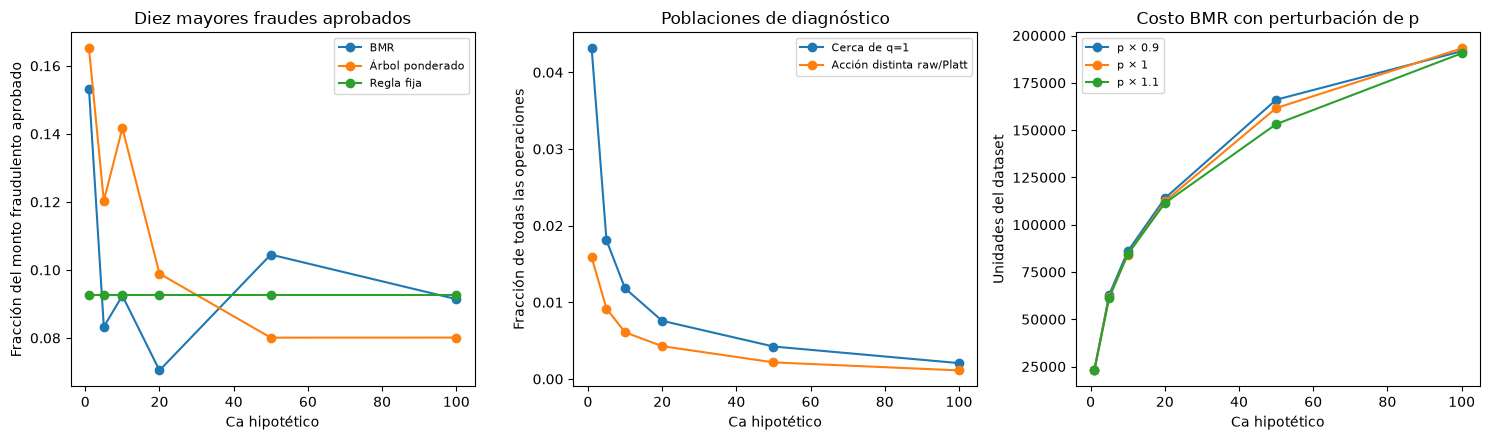

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for policy, group in concentration.loc[concentration.top_k_requested.eq(10)].groupby("strategy"):
    axes[0].plot(group.administrative_cost_ca, group.fraction_of_missed_amount, "o-", label=labels[policy])
axes[0].set(title="Diez mayores fraudes aprobados", ylabel="Fracción del monto fraudulento aprobado")
axes[1].plot(boundary.administrative_cost_ca, boundary.near_fraction, "o-", label="Cerca de q=1")
axes[1].plot(boundary.administrative_cost_ca, boundary.raw_platt_changed_actions / boundary.rows, "o-", label="Acción distinta raw/Platt")
axes[1].set(title="Poblaciones de diagnóstico", ylabel="Fracción de todas las operaciones")
for factor, group in sensitivity.groupby("probability_factor"):
    axes[2].plot(group.administrative_cost_ca, group.cost_total_proxy, "o-", label=f"p × {factor:g}")
axes[2].set(title="Costo BMR con perturbación de p", ylabel="Unidades del dataset")
for ax in axes:
    ax.set(xlabel="Ca hipotético")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "estabilidad_perdidas_y_frontera.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Evidencia y siguiente decisión metodológica

Exportamos únicamente siete tablas agregadas, dos figuras y registros de procedencia. Los scores y acciones por operación siguen siendo los del 05. Verificamos que los componentes de costo sumados por periodo reproduzcan el total anterior y que el factor 1 reproduzca BMR.

El siguiente paso será discutir estos hallazgos, justificar los escenarios hipotéticos y fijar el protocolo antes de prueba. Si proponemos cambiar tipos, representación o calibrador, será otro experimento documentado; esta etapa no altera automáticamente el predictor seleccionado. Sigue vigente la consulta histórica de estadísticas agregadas del periodo final.

In [7]:
tables = {"periodos": periods, "probabilidades": probabilities, "costos": costs,
    "calibracion_periodo_monto": amounts, "concentracion_perdidas": concentration,
    "frontera": boundary, "sensibilidad_probabilidad": sensitivity}
output_paths = []
for name, table in tables.items():
    relative = f"results/tables/estabilidad_{name}.csv"
    table.to_csv(ROOT / relative, index=False)
    output_paths.append(relative)
output_paths += ["results/figures/estabilidad_temporal.png", "results/figures/estabilidad_perdidas_y_frontera.png"]
verify_hashes(ROOT, {**inputs, **source_hashes})
if notebook_code_sha256(notebook_path) != code_hash:
    raise RuntimeError("Cambió el código durante el diagnóstico")
record = {"status": "complete", "completed_utc": datetime.now(timezone.utc).isoformat(),
    "protocol_sha256": sha256_file(protocol_path), "notebook_code_sha256": code_hash,
    "input_sha256": inputs, "source_sha256": source_hashes,
    "output_sha256": {p: sha256_file(ROOT / p) for p in output_paths},
    "rows": len(scores), "frauds": int(scores.isFraud.sum()), "periods": PERIOD_COUNT,
    "new_model_fitted": False, "new_calibrator_fitted": False, "model_loaded": False,
    "test_evaluated": False, "selection_changed": False, "final_protocol_frozen": False,
    "costs_hypothetical": True, "development_validation_previously_consulted": True,
    "period_cost_components_reconciled_with_05": True, "baseline_perturbation_reconciled_with_05": True,
    "python": platform.python_version(), "versions": {p: version(p) for p in ["numpy", "pandas", "scikit-learn", "matplotlib"]},
    "git_base_commit": subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip(),
    "working_tree_dirty": bool(subprocess.check_output(["git", "status", "--porcelain"], cwd=ROOT, text=True).strip())}
(TABLES / "estabilidad_config.json").write_text(json.dumps(record, ensure_ascii=False, indent=2), encoding="utf-8")
print("Diagnóstico completo; siete tablas y dos figuras. Modelo y protocolo final sin cambios; test sin puntuar.")

Diagnóstico completo; siete tablas y dos figuras. Modelo y protocolo final sin cambios; test sin puntuar.


## 8. Hallazgos de esta ejecución

La AP pasa de **0,53358** a **0,50981** y **0,46494**. Platt mejora Brier y log-loss en los tres periodos, aunque su probabilidad media sigue por debajo de la prevalencia. En [500,1000) también subestima la frecuencia y la exposición observadas en los tres periodos.

BMR tiene menor costo en **17 de 18** combinaciones periodo/Ca. En el periodo 3 con Ca=100 el árbol cuesta **60.920,554**, frente a **62.314,953** de BMR. El menor costo agregado del 05 no implica ganar en cada subperiodo.

Con Ca=10, el recall BMR baja de **59,01%** a **49,49%** entre el primer y tercer periodo; la mejora frente a fija pasa de **61,90%** a **46,89%**. Los diez mayores fraudes aprobados concentran **9,24%** de su pérdida residual, no del costo total.

Hay **497 operaciones** en la banda de frontera de Ca=10. Reducir p un 10% cambia 226 acciones y aumenta costo en 1.726,126; aumentarla un 10% cambia 260 y aumenta costo en 249,611. La banda de q no coincide exactamente con los cambios bajo factores de p; intervienen sus límites inversos y el recorte. Estos diagnósticos no seleccionan un factor ni prueban incertidumbre estadística.

El modelo, calibrador, Ca y políticas no se modificaron. El informe 06 conserva las cifras y limitaciones; falta fijar el protocolo final antes de prueba.